In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 04. Gauge symmetry

Infinitesimal diffeomorphisms act as $h_{\mu\nu}\to h_{\mu\nu}-\bar\nabla_\mu\xi_\nu-\bar\nabla_\nu\xi_\mu$.
We verify (i) $\mathcal L_\xi\bar g=\bar\nabla\xi+\bar\nabla\xi$, (ii) that pure-gauge perturbations solve the linearized equation,
(iii) the scalar-vector transformation laws and residual gauge freedom, and (iv) a numerical comparison of one configuration in three gauges.

In [2]:
from desitter_perturbations.background import symbolic_background
from desitter_perturbations.symbolic.curvature import Geometry
from desitter_perturbations.symbolic import gauge_transformations as gt, einstein_tensor as et
b = symbolic_background(); H=b["H"]; eta=b["eta"]; x,y,z=b["spatial"]
geom = Geometry(b["coords_conformal"], b["g_conformal"])
xi = [eta**2*x*y, x*z**2 + eta, y*eta*z, z**3*x]
print("Lie derivative equals covariant symmetrised gradient:", gt.lie_equals_covariant_residual(xi, geom) == sp.zeros(4,4))
hpg = gt.pure_gauge_perturbation(xi, geom)
print("dE[h_pure_gauge] == 0:", et.linearized_einstein_covariant(geom, hpg, 3*H**2)["dE"] == sp.zeros(4,4))

Lie derivative equals covariant symmetrised gradient: True


dE[h_pure_gauge] == 0: True


In [3]:
laws = gt.svt_transformation_laws()
print("shift of A    :", laws["dA"]); print("shift of psi  :", laws["dpsi"])
print("shift of S_x  :", laws["dS_x"]); print("shift of B_z  :", laws["dB_z"])
print("residuals against closed-form laws:", gt.check_svt_laws())

shift of A    : -Derivative(T(eta, z), eta) + T(eta, z)/eta
shift of psi  : -T(eta, z)/eta
shift of S_x  : -Derivative(Lx(eta, z), eta)
shift of B_z  : Derivative(T(eta, z), z) - Derivative(L(eta, z), eta, z)
residuals against closed-form laws: {'A': 0, 'psi': 0, 'S_x': 0, 'B_z': 0, 'E_zz': 0, 'F_xz': 0}


Residual gauge freedom: Newtonian gauge ($B=E=0$) keeps $T=L=0$ for $k\neq0$ (none). Synchronous gauge ($A=B=0$) keeps $T=C/a$ (one function of space).
Spatially flat gauge ($\psi=E=0$) requires $\mathcal H T=0$, hence none for $\mathcal H\neq0$.

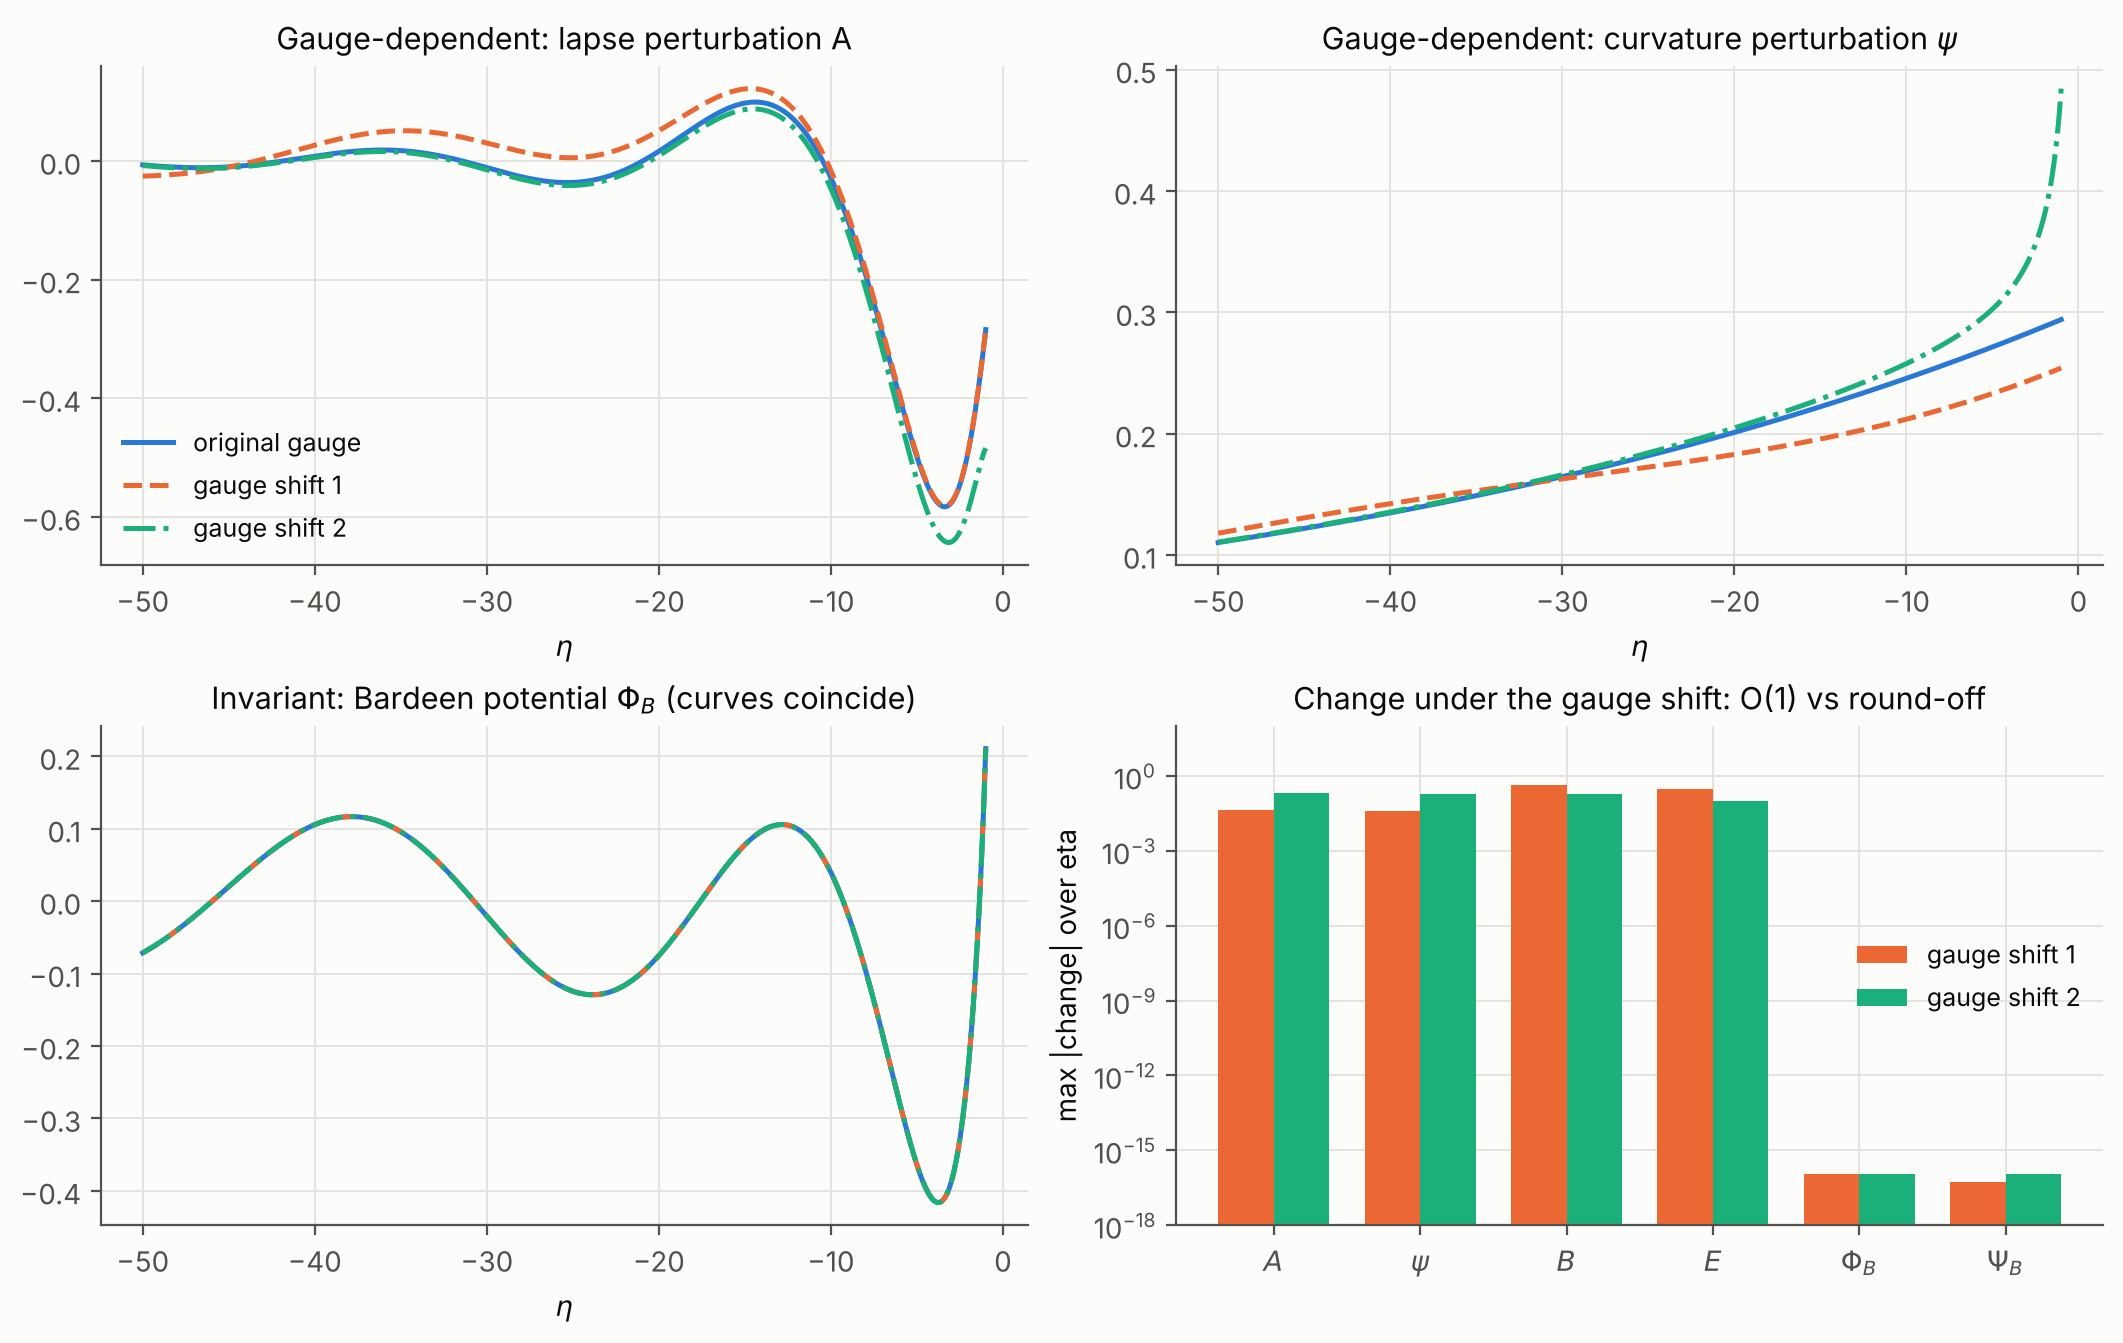

In [4]:
from desitter_perturbations.visualization import gauge_plots as gaup
show(gaup.plot_gauge_comparison())